### Lava flow data for ESRP

Metadata:

name: refers to the map name or common name of the lava flow

type: Classification of lava flow field type based on whether the lava flow field includes a GESRP shield volcano, the lava flow field is GESRP but does not have a shield volcano, or the lava flow originates from a CoM vent. Type 3 refers to a CoM lava flow, type 1 refers to GESRP lava flow field with shield volcano, type 2 refers to GESRP lava flow field without shield volcano (e.g., fissure, spatter rampart, scoria cone) 

length: field measured length of the lava flow (km), from Christiansen reort

est-area: field estimate of the lava flow area (km2), including shield area, from Christiansen

est_volume: field estimate of the lava flow field volume (including shied area) (km3), from Christiansen

burial:  a classification of the degree of burial of the lava flow. Only lava flows have estimated parameters if they are largely unbried. Nevertheless, some lava flow fields are partially buried on the ESRP but can still have parameters estimate. Burial category 1 means the lava flow field is basically not buried (except for very local cover such as loess). Burial category 2 means the lava flow is partially buried by sediments or by younger lava flows, but the area and volume of the lava flow can still be deduced.

tfield: field estimate of the thickness of the lava flow (m), from Christiansen

flow_area: this is the area of the lava flow field minus the area of the shield volcano edifice (km2)

flow_volume: this is the volume of the lava flow field, not including the edifice of the shield volcano (km3)

tcalc: calculated thickness of the lava flow (m)

tmolasses: binned thickness of the lava flow used in the MOLASSES code simulations (m)

magnitude: refers to the size of the shield volcano associated with the lava flow field (small shield: 1, medium shield:2, large shield:3, no shield: -1). Undetermined magnitudes are reported as "0".

shield_diameter: the geometric average diameter of the shield volcano - used ot calculate the area of the shield volcano using an equivalent circle (km). The shield diameter is used to calculate the area of the shield volcano and volume of the shield volcano:

 $$ A_{shield} = \pi b^2/4 $$
 where $b$ is the shield equivalent diameter.

 Then the shield volume is:
 $$V_{shield} = \pi b^2 c/12000 $$
 where:$c$ is the edifice height

corrected_area: the lava flow field are corrected for the area of the shield volcano and adjusted for burial part of the lava flow field (km2). The correction for burial is found by multiplying the uncorreted value by the ratio of the mean area of unburied flows to that of partially buried flows, obviously an approximation.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib import rcParams


rcParams['pdf.fonttype'] = 42  # Use TrueType fonts in PDF (Type 42 embeds TTF)


In [3]:
lava = pd.read_csv("./LAVA_DATA.DAT")
lava.iloc[60:80]

,name,type,length,est_area,est_volume,burial,tfield,flow_area,flow_volume,tcalc,tmolasses,magnitude,shield_diameter,corrected_area,shield_ht
60,N. Robbers,2,5.3,5.0,ND,1,5.0,5.0,0.02,5.0,5,–1,0.0,5,0
61,S. Robbers,2,3.3,3.0,ND,1,7.5,3.0,0.02,7.5,10,–1,0.0,3,0
62,Turnbull Butte 5211,2,21.4,52.0,ND,2,5.0,52.0,0.26,5.0,5,–1,0.0,81,0
63,Sect. 2/3 boundary,2,6.3,9.0,ND,2,11.0,9.0,0.10,11.0,10,–1,0.0,14,0
64,Minidoka and Larkspur flows,3,38.2,360.0,3.6,1,10.0,360.0,3.60,10.0,10,–1,0.0,360,0
65,Blue Dragon flow,3,21.5,297.5,1.9,1,6.4,297.5,1.90,6.4,5,–1,0.0,297,0
66,Sunset,3,18.6,100.0,ND,1,10.3,100.0,1.03,10.3,10,–1,0.0,100,0
67,Carey,3,52.3,230.0,ND,2,8.0,230.0,1.84,8.0,10,–1,0.0,355,0
68,Big Craters - N,3,5.8,9.0,0.09,1,10.0,9.0,0.09,10.0,10,–1,0.0,9,0
69,Black Top Butte flow,3,0.9,0.7,0.01,2,5.0,0.7,0.01,10.0,10,–1,0.0,1,0


In [4]:
#example adjustment for shield volume (shield volume should not be included in the lava flow volume for MOLASSES
#vent53
total_volume = 0.21 #km3
shield_diameter = 4.1 #km
shield_ht = 26 #m
est_shield_vol = np.pi*(shield_diameter/2)**2*(shield_ht/1000)/3
print("v5317 shield volume =", est_shield_vol, "km3")
print("flow volume = ", total_volume - est_shield_vol, "km3")

#rocky butte
total_volume = 16.1 #km3
shield_diameter = 12.4 #km
shield_ht = 114 #m
est_shield_vol = np.pi*(shield_diameter/2)**2*(shield_ht/1000)/3
print("Rocky Butte shield volume =", est_shield_vol, "km3")
print("flow volume = ", total_volume - est_shield_vol, "km3")


v5317 shield volume = 0.11442204043149623 km3
flow volume =  0.09557795956850376 km3
Rocky Butte shield volume = 4.588987220951684 km3
flow volume =  11.511012779048318 km3


In [5]:
#create a column of shield cone volume in km3
lava["shield_vol"] = np.pi*(lava["shield_diameter"]/2)**2*(lava["shield_ht"]/1000)/3
# Convert est_volume to numeric, setting errors='coerce' turns 'ND' into NaN
lava["est_volume"] = pd.to_numeric(lava["est_volume"], errors='coerce')

# Now use np.where for vectorized assignment
lava["flow_field_vol"] = np.where(
    lava["est_volume"].isna(),
    lava["flow_volume"],
    lava["est_volume"] - lava["shield_vol"]
)

lava["shield_lava_volume"] =  np.pi*(lava["shield_diameter"]/2)**2*lava["tfield"]/1000

lava["flow_field_vol"] = np.where(
    lava["flow_field_vol"] < lava["shield_lava_volume"],
    lava["shield_lava_volume"],
    lava["flow_field_vol"]
)
lava.head()

,name,type,length,est_area,est_volume,burial,tfield,flow_area,flow_volume,tcalc,tmolasses,magnitude,shield_diameter,corrected_area,shield_ht,shield_vol,flow_field_vol,shield_lava_volume
0,Vent 5317,1,9.7,27.0,0.21,1,6.5,13.8,0.06,4.4,5,1,4.1,14,26,0.114422,0.095578,0.085817
1,W sect 22,1,9.1,31.0,1.00,1,30.0,25.4,0.81,32.1,25,2,2.7,25,62,0.118328,0.881672,0.171767
2,Pond Butte,1,9.0,37.0,0.35,1,10.0,24.1,0.26,10.7,10,3,4.1,24,26,0.114422,0.235578,0.132025
3,Vent 5410,1,8.6,54.0,0.37,2,23.0,40.1,0.85,21.2,20,3,4.2,62,84,0.387924,0.318652,0.318652
4,Fingers Butte,1,11.0,58.0,1.30,1,21.5,45.4,0.97,21.3,20,3,4.0,45,67,0.280649,1.019351,0.270177


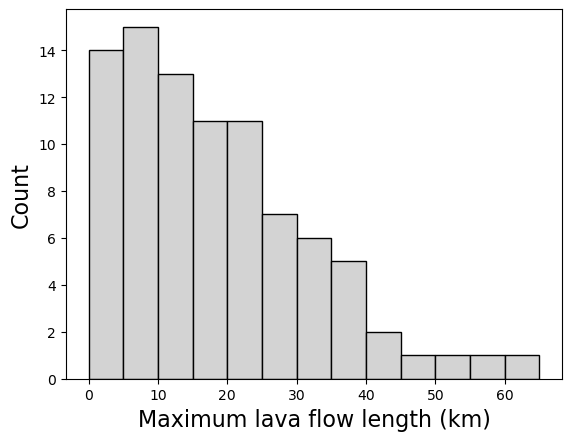

In [6]:
#histogram of lava flow lengths

#convert to series
lengths = lava["length"].to_numpy()

# Set bin width
bin_width = 5
# Create an array of bin edges based on bin width
bin_edges = np.arange(0,65 + bin_width, bin_width)



plt.hist(lengths, bins=bin_edges,  color="lightgray", edgecolor='black' )
plt.xlabel("Maximum lava flow length (km)", fontsize=16)
plt.ylabel("Count", fontsize=16)
plt.savefig("./lava_length.pdf")
plt.show()

In [7]:
unique_values = lava['magnitude'].unique()
print(unique_values)

[' 1' ' 2' ' 3' ' 0' ' –1']


11.511012779048318


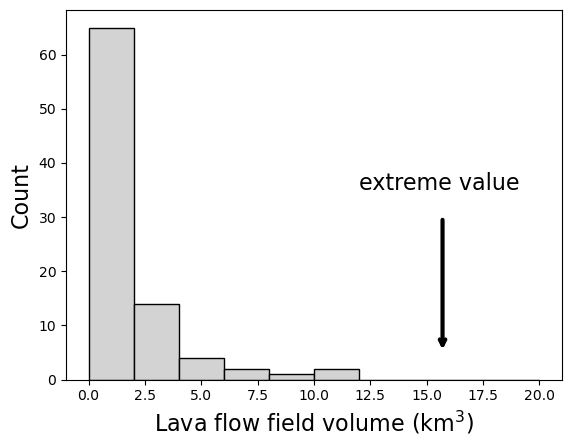

In [8]:
#histogram of lava flow field columes

#convert to series
volumes = lava["flow_field_vol"].to_numpy()
print (volumes.max())
# Set bin width
bin_width = 2
# Create an array of bin edges based on bin width
bin_edges = np.arange(0,20 + bin_width, bin_width)



plt.hist(volumes, bins=bin_edges,  color="lightgray", edgecolor='black' )
plt.xlabel("Lava flow field volume (km$^3$)", fontsize=16)
plt.ylabel("Count", fontsize=16)
plt.text(12,35, "extreme value", fontsize=16)
# Draw thick downward arrow
plt.annotate(
    '',  # no text
    xy=(15.7, 5),            # arrowhead location
    xytext=(15.7, 30),       # start of the arrow
    arrowprops=dict(
        arrowstyle='->',
        color='black',
        lw=3,                # line width (thickness)
    )
)
plt.savefig("./lava_volume.pdf")
plt.show()

In [9]:
#accounting for burial. 
# First find the mean area of shield lava flow fields that are unburied:
mean_unburied_area = lava[lava['burial'] == 1]['est_area'].mean()
print(mean_unburied_area)

mean_buried_area = lava[lava['burial'] == 2]['est_area'].mean()
print(mean_buried_area)

#ratio - correction facto for buried lava flow area:
correction_factor = mean_unburied_area/mean_buried_area 
print(correction_factor)

160.07222222222222
112.86153846153846
1.418306221979886


In [10]:
#find volume of GESRP and COM lava flows

# 1. all GESRP
GESRP_volume  = pd.to_numeric(lava[lava['type'] != 3]['est_volume'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_gesrp_vol = GESRP_volume.mean()
median_gesrp = GESRP_volume.median()
print ("Mean and median GESRP volume = ", mean_gesrp_vol, median_gesrp, "km3" )

#2. GESRP shields
GESRP_volume_shield  = pd.to_numeric(lava[lava['type'] ==1]['est_volume'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_gesrp_shield_vol = GESRP_volume_shield.mean()
median_gesrp_shield = GESRP_volume_shield.median()
#print ("Mean and median GESRP shield volume = ", mean_gesrp_shield_vol, median_gesrp_shield, "km3" )

#3 GESRP nonshields

#4 COM
COM_volume  = pd.to_numeric(lava[lava['type'] ==3]['est_volume'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_COM_vol = COM_volume.mean()
median_COM = COM_volume.median()
print ("Mean and median COM volume = ", mean_COM_vol, median_COM, "km3" )


# 1. all GESRP - area
GESRP_area  = pd.to_numeric(lava[lava['type'] != 3]['est_area'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_gesrp_area = GESRP_area.mean()
median_gesrp = GESRP_area.median()
print ("Mean and median GESRP area = ", mean_gesrp_area, median_gesrp, "km2" )

#2. GESRP shields
GESRP_area_shield  = pd.to_numeric(lava[lava['type'] ==1]['est_area'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_gesrp_shield_area = GESRP_area_shield.mean()
median_gesrp_shield = GESRP_area_shield.median()
print ("Mean and median GESRP shield area = ", mean_gesrp_shield_area, median_gesrp_shield, "km2" )

#3 GESRP nonshields
GESRP_area_nonshield  = pd.to_numeric(lava[lava['type'] ==2]['est_area'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_gesrp_nonshield_area = GESRP_area_nonshield.mean()
median_gesrp_nonshield = GESRP_area_nonshield.median()
print ("Mean and median GESRP non-shield area = ", mean_gesrp_nonshield_area, median_gesrp_nonshield, "km2" )
#4 COM
COM_area  = pd.to_numeric(lava[lava['type'] ==3]['est_area'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_COM_area = COM_area.mean()
median_COM = COM_area.median()
print ("Mean and median COM area = ", mean_COM_area, median_COM, "km2" )



Mean and median GESRP volume =  3.4677551020408166 1.9 km3
Mean and median COM volume =  0.8363636363636363 0.44999999999999996 km3
Mean and median GESRP area =  148.109375 76.0 km2
Mean and median GESRP shield area =  183.0408163265306 124.0 km2
Mean and median GESRP non-shield area =  34.0 24.0 km2
Mean and median COM area =  89.68333333333332 50.05 km2


In [11]:
# create a column in which Christiansen's areas are currected for burial
lava['corrected'] = np.where(lava['burial'] == 2, lava['est_area'] * correction_factor, lava['est_area'])


In [12]:
#maximum lava length
max_row = lava.loc[lava['length'].idxmax()]
print(max_row)
#total number of lengths
lava_len = len(lava['length'])
print(lava_len)

#second longestflow
second_largest = lava['length'].drop_duplicates().nlargest(2).iloc[-1]

print(second_largest)

name                  Grassy and Laidlaw Lake combined
type                                                 3
length                                            64.0
est_area                                         190.0
est_volume                                        1.25
burial                                               2
tfield                                             6.6
flow_area                                        190.0
flow_volume                                       1.25
tcalc                                              6.6
tmolasses                                            5
magnitude                                           –1
shield_diameter                                    0.0
corrected_area                                     293
shield_ht                                            0
shield_vol                                         0.0
flow_field_vol                                    1.25
shield_lava_volume                                 0.0
corrected 

In [13]:
# mean lava flow thickness Com vs GESRP
COM_thick  = pd.to_numeric(lava[lava['type'] ==3]['tfield'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_COM_thick = COM_thick.mean()
median_COM = COM_thick.median()
print ("Mean and median COM thick = ", mean_COM_thick, median_COM, "m" )

# mean lava flow thickness Com vs GESRP
GESRP_thick  = pd.to_numeric(lava[lava['type'] !=3]['tfield'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_GESRP_thick = GESRP_thick.mean()
median_GESRP = GESRP_thick.median()
print ("Mean and median GESRP thick = ", mean_GESRP_thick, median_GESRP, "m" )

# mean lava flow thickness Com vs GESRP
GESRP_thick_nonshield  = pd.to_numeric(lava[lava['type'] ==2]['tfield'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_GESRP_thick = GESRP_thick_nonshield.mean()
median_GESRP = GESRP_thick_nonshield.median()
print ("Mean and median GESRP thick nonshield = ", mean_GESRP_thick, median_GESRP, "m" )

# mean lava flow thickness Com vs GESRP
GESRP_thick_shield  = pd.to_numeric(lava[lava['type'] ==1]['tfield'], errors='coerce')
#gesrp_vol1 = ['values'] = pd.to_numeric(df['values'], errors='coerce')
mean_GESRP_thick = GESRP_thick_shield.mean()
median_GESRP = GESRP_thick_shield.median()
print ("Mean and median GESRP thick shield = ", mean_GESRP_thick, median_GESRP, "m" )


Mean and median COM thick =  9.762500000000001 9.75 m
Mean and median GESRP thick =  18.4234375 15.75 m
Mean and median GESRP thick nonshield =  8.493333333333334 10.0 m
Mean and median GESRP thick shield =  21.46326530612245 20.0 m


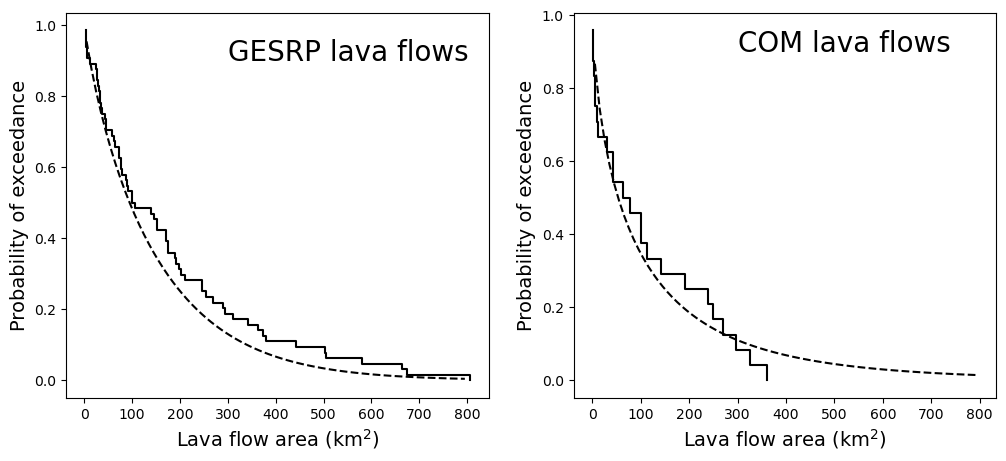

In [14]:
#adjust weights for shield size, to correct for bias in lava flow sampling

#create the empirical ccdf gesrp
corrected_area_gesrp = lava.loc[lava['type'] != 3, 'corrected'].to_numpy()
sorted_corrected_gesrp = np.sort(corrected_area_gesrp)
ccdf_gesrp = 1- np.arange(1, len(sorted_corrected_gesrp) + 1)/len(sorted_corrected_gesrp)

#create the model ccdf gesrp
x_gesrp = np.arange(5,800,10)
ccdf_model_gesrp = 0.8 * np.exp(-(0.0058 * x_gesrp)**1.083) + 0.2 * np.exp(-(0.0241*x_gesrp)**0.866)


#create the empirical ccdf com
corrected_area_com = lava.loc[lava['type'] == 3, 'corrected'].to_numpy()
sorted_corrected_com = np.sort(corrected_area_com)
ccdf_com = 1- np.arange(1, len(sorted_corrected_com) + 1)/len(sorted_corrected_com)

#create the model ccdf gesrp
x_com = np.arange(5,800,10)
ccdf_model_com = np.exp(-(0.0109*x_com)**0.669)



# Create a figure with 1 row and 2 columns of subplots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))


axes[0].step(sorted_corrected_gesrp, ccdf_gesrp, where='post', color='black', linestyle='-')
axes[0].plot(x_gesrp,ccdf_model_gesrp,  color='black', linestyle='--')
axes[0].set_xlabel("Lava flow area (km$^2$)", fontsize=14)
axes[0].set_ylabel("Probability of exceedance", fontsize=14)
axes[0].text(300, 0.9, 'GESRP lava flows', fontsize=20, color='black')

axes[1].step(sorted_corrected_com, ccdf_com, where='post' , color='black', linestyle='-')
axes[1].plot(x_com,ccdf_model_com,  color='black', linestyle='--')
axes[1].set_xlabel("Lava flow area (km$^2$)", fontsize=14)
axes[1].set_ylabel("Probability of exceedance", fontsize=14)
axes[1].text(300, 0.9, 'COM lava flows', fontsize=20, color='black')

plt.savefig("./prob_exceedance_lava_flows.pdf")
plt.show()

In [15]:
import pandas as pd
from docx import Document

final_data = lava[['name', 'type', 'burial','length','est_area', 'corrected', 'tfield', 'shield_vol', 'flow_field_vol']]
final_data['corrected']= round(final_data['corrected'],1) 
final_data['shield_vol']= round(final_data['shield_vol'],3) 
final_data['flow_field_vol']= round(final_data['flow_field_vol'],3) 

#final_data = final_data.rename(columns={'magnitude': 'M'})
final_data = final_data.rename(columns={'burial': 'bur.'})
final_data = final_data.rename(columns={'est_area': 'area'})
final_data = final_data.rename(columns={'est_volume': 'vol'})
final_data = final_data.rename(columns={'tfield': 'thick.'})
final_data = final_data.rename(columns={'shield_vol': 's.v.'})
# Create a Word document
final_data = final_data.rename(columns={'flow_field_vol': 'f.f.v.'})
# Create a Word document
# Create a Word document
# Create a Word document
doc = Document()
doc.add_heading('Data Table', level=1)

# Add table with one extra row for headers
table = doc.add_table(rows=1, cols=len(final_data.columns))

# Add header row
hdr_cells = table.rows[0].cells
for i, column in enumerate(final_data.columns):
    hdr_cells[i].text = str(column)

# Add the data rows
for index, row in final_data.iterrows():
    row_cells = table.add_row().cells
    for i, value in enumerate(row):
        row_cells[i].text = str(value)

# Save the document
doc.save('./data_table.docx')


/tmp/ipykernel_2327/2246592516.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data['corrected']= round(final_data['corrected'],1)
/tmp/ipykernel_2327/2246592516.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data['shield_vol']= round(final_data['shield_vol'],3)
/tmp/ipykernel_2327/2246592516.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http